# Truncated Bar Axis vs. Zero Baseline

**Family:** Bad vs. good &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Bad vs. good:* Common chart mistakes, each shown next to a better alternative that fixes it.

## Design purpose

Bars encode value by length, so a bar chart whose y-axis starts above zero makes small differences look large. In the example a 5-point gap looks like a 6-fold one. Readers judge the bar lengths, not the tick labels.

## When to use

- Always start bar and column charts at zero
- If the small differences are the story, switch to a dot plot, which may use a zoomed axis because it encodes position, not length

## Avoid when

- Bar charts of values clustered far from zero (satisfaction scores, percentages near 100)
- Dashboard defaults that auto-scale the y-axis to the data range

## Alternatives

- Dot plot / Cleveland dot plot with a non-zero axis
- Deviation bar chart from a meaningful reference (target, average)

## Design tips

- Bars and areas need a zero baseline; lines and dots do not
- Label the values directly if the differences need to be read precisely
- Show differences from a reference point explicitly if they matter

## Example

Patient-satisfaction scores (out of 100) for four hospital wards.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
df = pd.DataFrame({"ward": ["Ward A", "Ward B", "Ward C", "Ward D"],
                   "score": [92.0, 93.5, 95.0, 97.0]})
df

,ward,score
0,Ward A,92.0
1,Ward B,93.5
2,Ward C,95.0
3,Ward D,97.0


### Plot

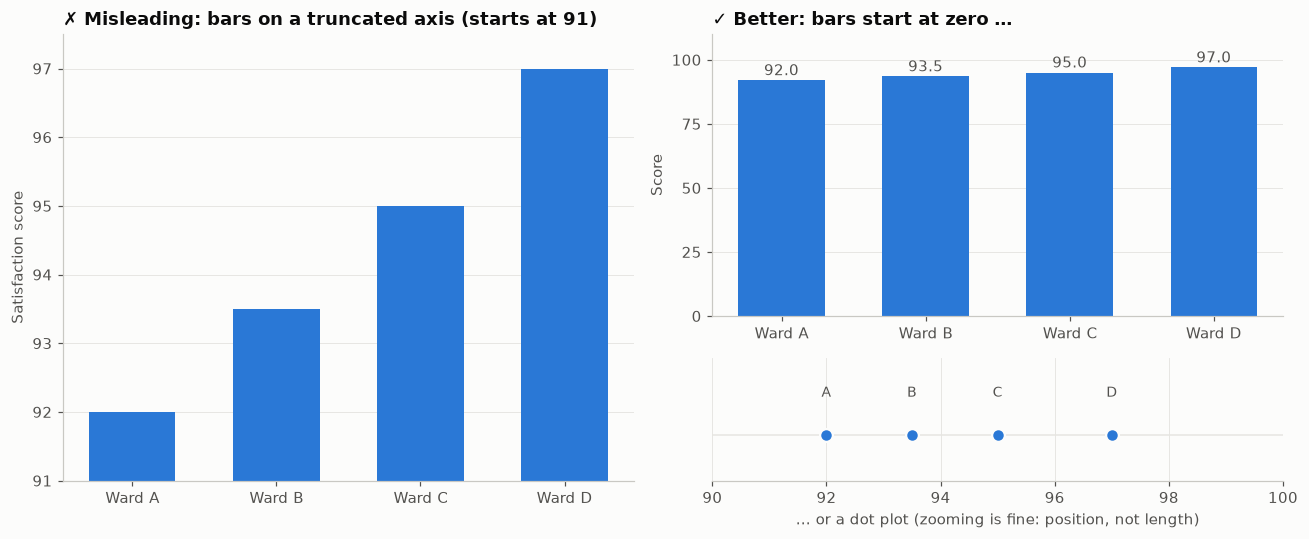

In [3]:
fig = plt.figure(figsize=(12, 5))
gs = fig.add_gridspec(2, 2, height_ratios=[3, 1.3], width_ratios=[1, 1])
ax1 = fig.add_subplot(gs[:, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 1])

# Misleading: bars on an axis that starts at 91.
ax1.bar(df["ward"], df["score"], color=PALETTE[0], width=0.6)
ax1.set_ylim(91, 97.5)
ax1.set_ylabel("Satisfaction score")
ax1.set_title("✗ Misleading: bars on a truncated axis (starts at 91)", fontsize=11.5)
ax1.grid(axis="x", visible=False)

# Better: bars from zero, values labeled ...
ax2.bar(df["ward"], df["score"], color=PALETTE[0], width=0.6)
for x, v in enumerate(df["score"]):
    ax2.text(x, v + 2, f"{v:.1f}", ha="center", fontsize=9.5, color="#52514e")
ax2.set_ylim(0, 110)
ax2.set_yticks([0, 25, 50, 75, 100])
ax2.set_ylabel("Score")
ax2.set_title("✓ Better: bars start at zero …", fontsize=11.5)
ax2.grid(axis="x", visible=False)

# ... or a dot plot, which may zoom because it encodes position.
ax3.hlines(0, 90, 100, color="#e6e5e1", linewidth=1)
ax3.scatter(df["score"], np.zeros(len(df)), s=70, color=PALETTE[0], zorder=3,
            edgecolor="#fcfcfb", linewidth=1.5)
for v, w in zip(df["score"], df["ward"]):
    ax3.text(v, 0.5, w.replace("Ward ", ""), ha="center", fontsize=9, color="#52514e")
ax3.set_xlim(90, 100)
ax3.set_ylim(-0.6, 1.0)
ax3.set_yticks([])
ax3.spines["left"].set_visible(False)
ax3.grid(axis="y", visible=False)
ax3.set_xlabel("… or a dot plot (zooming is fine: position, not length)")
fig.tight_layout()
plt.show()

## How to read it

On the left, Ward D's bar looks about six times taller than Ward A's. On the right, the true lengths show scores of 92 and 97, which are nearly the same. The dot plot below the bars zooms in honestly, because position (not length) carries the value.

---
Standalone script: [`truncated_bar_axis.py`](truncated_bar_axis.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)